In [220]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Обучение линейной модели

## Разведочный анализ данных

In [221]:
TARGET = 'RiskScore'
train = pd.read_csv('train.csv')
train

,ApplicationDate,Age,AnnualIncome,CreditScore,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,HomeOwnershipStatus,MonthlyDebtPayments,...,JobTenure,EmploymentStatus,EducationLevel,Experience,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,RiskScore
0,2010-06-26,27.0,66829.0,549.0,17290.0,60.0,Divorced,1.0,Rent,1095.0,...,4.0,Employed,Associate,4.0,35067.0,0.257790,0.251465,508.970230,0.288013,66.176500
1,1996-09-23,55.0,172147.0,850.0,16110.0,36.0,Widowed,1.0,Mortgage,211.0,...,2.0,Employed,High School,33.0,27001.0,0.086110,0.093173,514.675859,0.050585,28.495737
2,2015-01-19,51.0,300000.0,850.0,38436.0,36.0,Married,0.0,Mortgage,546.0,...,3.0,Employed,Bachelor,28.0,278382.0,0.108436,0.115443,1268.276385,0.072571,34.488104
3,1981-05-12,25.0,34683.0,847.0,19186.0,48.0,Married,0.0,Other,153.0,...,3.0,Employed,High School,0.0,9224.0,0.100686,0.112822,498.505187,0.225415,36.910753
4,1995-05-07,55.0,300000.0,850.0,30437.0,48.0,Single,2.0,Rent,562.0,...,5.0,Employed,Bachelor,31.0,4502.0,0.110437,0.089037,756.035156,0.052721,31.347091
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11012,2010-07-10,57.0,300000.0,850.0,14756.0,48.0,Married,2.0,Own,620.0,...,4.0,Employed,Associate,38.0,167544.0,0.094756,0.106387,378.792448,0.039952,32.440586
11013,2003-10-22,28.0,15000.0,300.0,51361.0,96.0,Single,1.0,Own,696.0,...,3.0,Employed,Bachelor,5.0,116879.0,0.446361,0.401087,1793.042130,1.991234,67.673170
11014,1983-05-12,23.0,15000.0,302.0,30724.0,72.0,Married,3.0,Rent,413.0,...,3.0,Self-Employed,Associate,0.0,250778.0,0.404724,0.360670,1047.672294,1.168538,75.292707
11015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Видно, что есть полностью пустые строки

In [222]:
train = train.dropna(how='all', ignore_index=True)
print(train[train.isna().any(axis=1)].info())
print(f'Строк с пропусками: {len(train[train.isna().any(axis=1)])}')

<class 'pandas.DataFrame'>
Index: 501 entries, 13 to 10486
Data columns (total 35 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ApplicationDate             501 non-null    str    
 1   Age                         501 non-null    float64
 2   AnnualIncome                501 non-null    float64
 3   CreditScore                 0 non-null      float64
 4   LoanAmount                  0 non-null      float64
 5   LoanDuration                501 non-null    float64
 6   MaritalStatus               501 non-null    str    
 7   NumberOfDependents          501 non-null    float64
 8   HomeOwnershipStatus         501 non-null    str    
 9   MonthlyDebtPayments         0 non-null      float64
 10  CreditCardUtilizationRate   501 non-null    float64
 11  NumberOfOpenCreditLines     501 non-null    float64
 12  NumberOfCreditInquiries     501 non-null    float64
 13  DebtToIncomeRatio           501 non-null    floa

In [223]:
train = train.dropna(ignore_index=True)
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 9986 entries, 0 to 9985
Data columns (total 35 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ApplicationDate             9986 non-null   str    
 1   Age                         9986 non-null   float64
 2   AnnualIncome                9986 non-null   float64
 3   CreditScore                 9986 non-null   float64
 4   LoanAmount                  9986 non-null   float64
 5   LoanDuration                9986 non-null   float64
 6   MaritalStatus               9986 non-null   str    
 7   NumberOfDependents          9986 non-null   float64
 8   HomeOwnershipStatus         9986 non-null   str    
 9   MonthlyDebtPayments         9986 non-null   float64
 10  CreditCardUtilizationRate   9986 non-null   float64
 11  NumberOfOpenCreditLines     9986 non-null   float64
 12  NumberOfCreditInquiries     9986 non-null   float64
 13  DebtToIncomeRatio           9986 non-null   

In [224]:
print(f'Дублирующихся строк: {train.duplicated().sum()}')
train = train.drop_duplicates(ignore_index=True)

Дублирующихся строк: 457


In [225]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,9529.0,39.875223,1.159521e+01,1.800000e+01,32.000000,40.000000,48.000000,8.000000e+01
AnnualIncome,9529.0,131707.601952,1.159892e+05,1.500000e+04,21067.000000,88998.000000,257409.000000,7.485080e+05
CreditScore,9529.0,678.223318,1.750362e+02,3.000000e+02,550.000000,723.000000,850.000000,8.500000e+02
LoanAmount,9529.0,29757.317137,2.721287e+04,1.063000e+03,12633.000000,21803.000000,37086.000000,4.189970e+05
LoanDuration,9529.0,53.418827,2.439347e+01,1.200000e+01,36.000000,48.000000,60.000000,1.200000e+02
NumberOfDependents,9529.0,1.568265,1.419023e+00,0.000000e+00,0.000000,1.000000,3.000000,6.000000e+00
MonthlyDebtPayments,9529.0,547.004093,5.027810e+02,1.300000e+01,234.000000,399.000000,687.000000,1.087900e+04
CreditCardUtilizationRate,9529.0,0.284779,1.592656e-01,3.673558e-03,0.159134,0.263013,0.392255,9.146347e-01
NumberOfOpenCreditLines,9529.0,3.034841,1.740828e+00,0.000000e+00,2.000000,3.000000,4.000000,1.200000e+01
NumberOfCreditInquiries,9529.0,0.981320,9.903329e-01,0.000000e+00,0.000000,1.000000,2.000000,6.000000e+00


In [226]:
def draw_dists(df: pd.DataFrame):
    num_cols = df.select_dtypes(include='number').columns
    ncols = 4
    nrows = math.ceil(len(num_cols) / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5, nrows * 4))
    axes = axes.flatten()

    for i, col in enumerate(num_cols):
        sns.histplot(df, x=col, ax=axes[i])

    for j in range(len(num_cols), len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

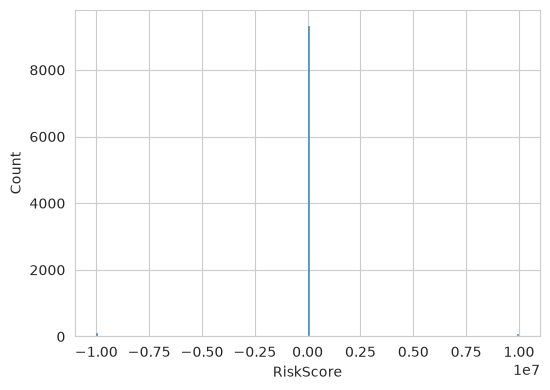

In [227]:
draw_dists(train[[TARGET]])

In [228]:
mask = (train.RiskScore < -1000) | (train.RiskScore > 1000)
print(f'Количество выбросов: {len(train[mask])}')
train = train[~mask]

Количество выбросов: 197


In [229]:
print(f'Осталось строк: {len(train)}')

Осталось строк: 9332


Посмотрим на распределения

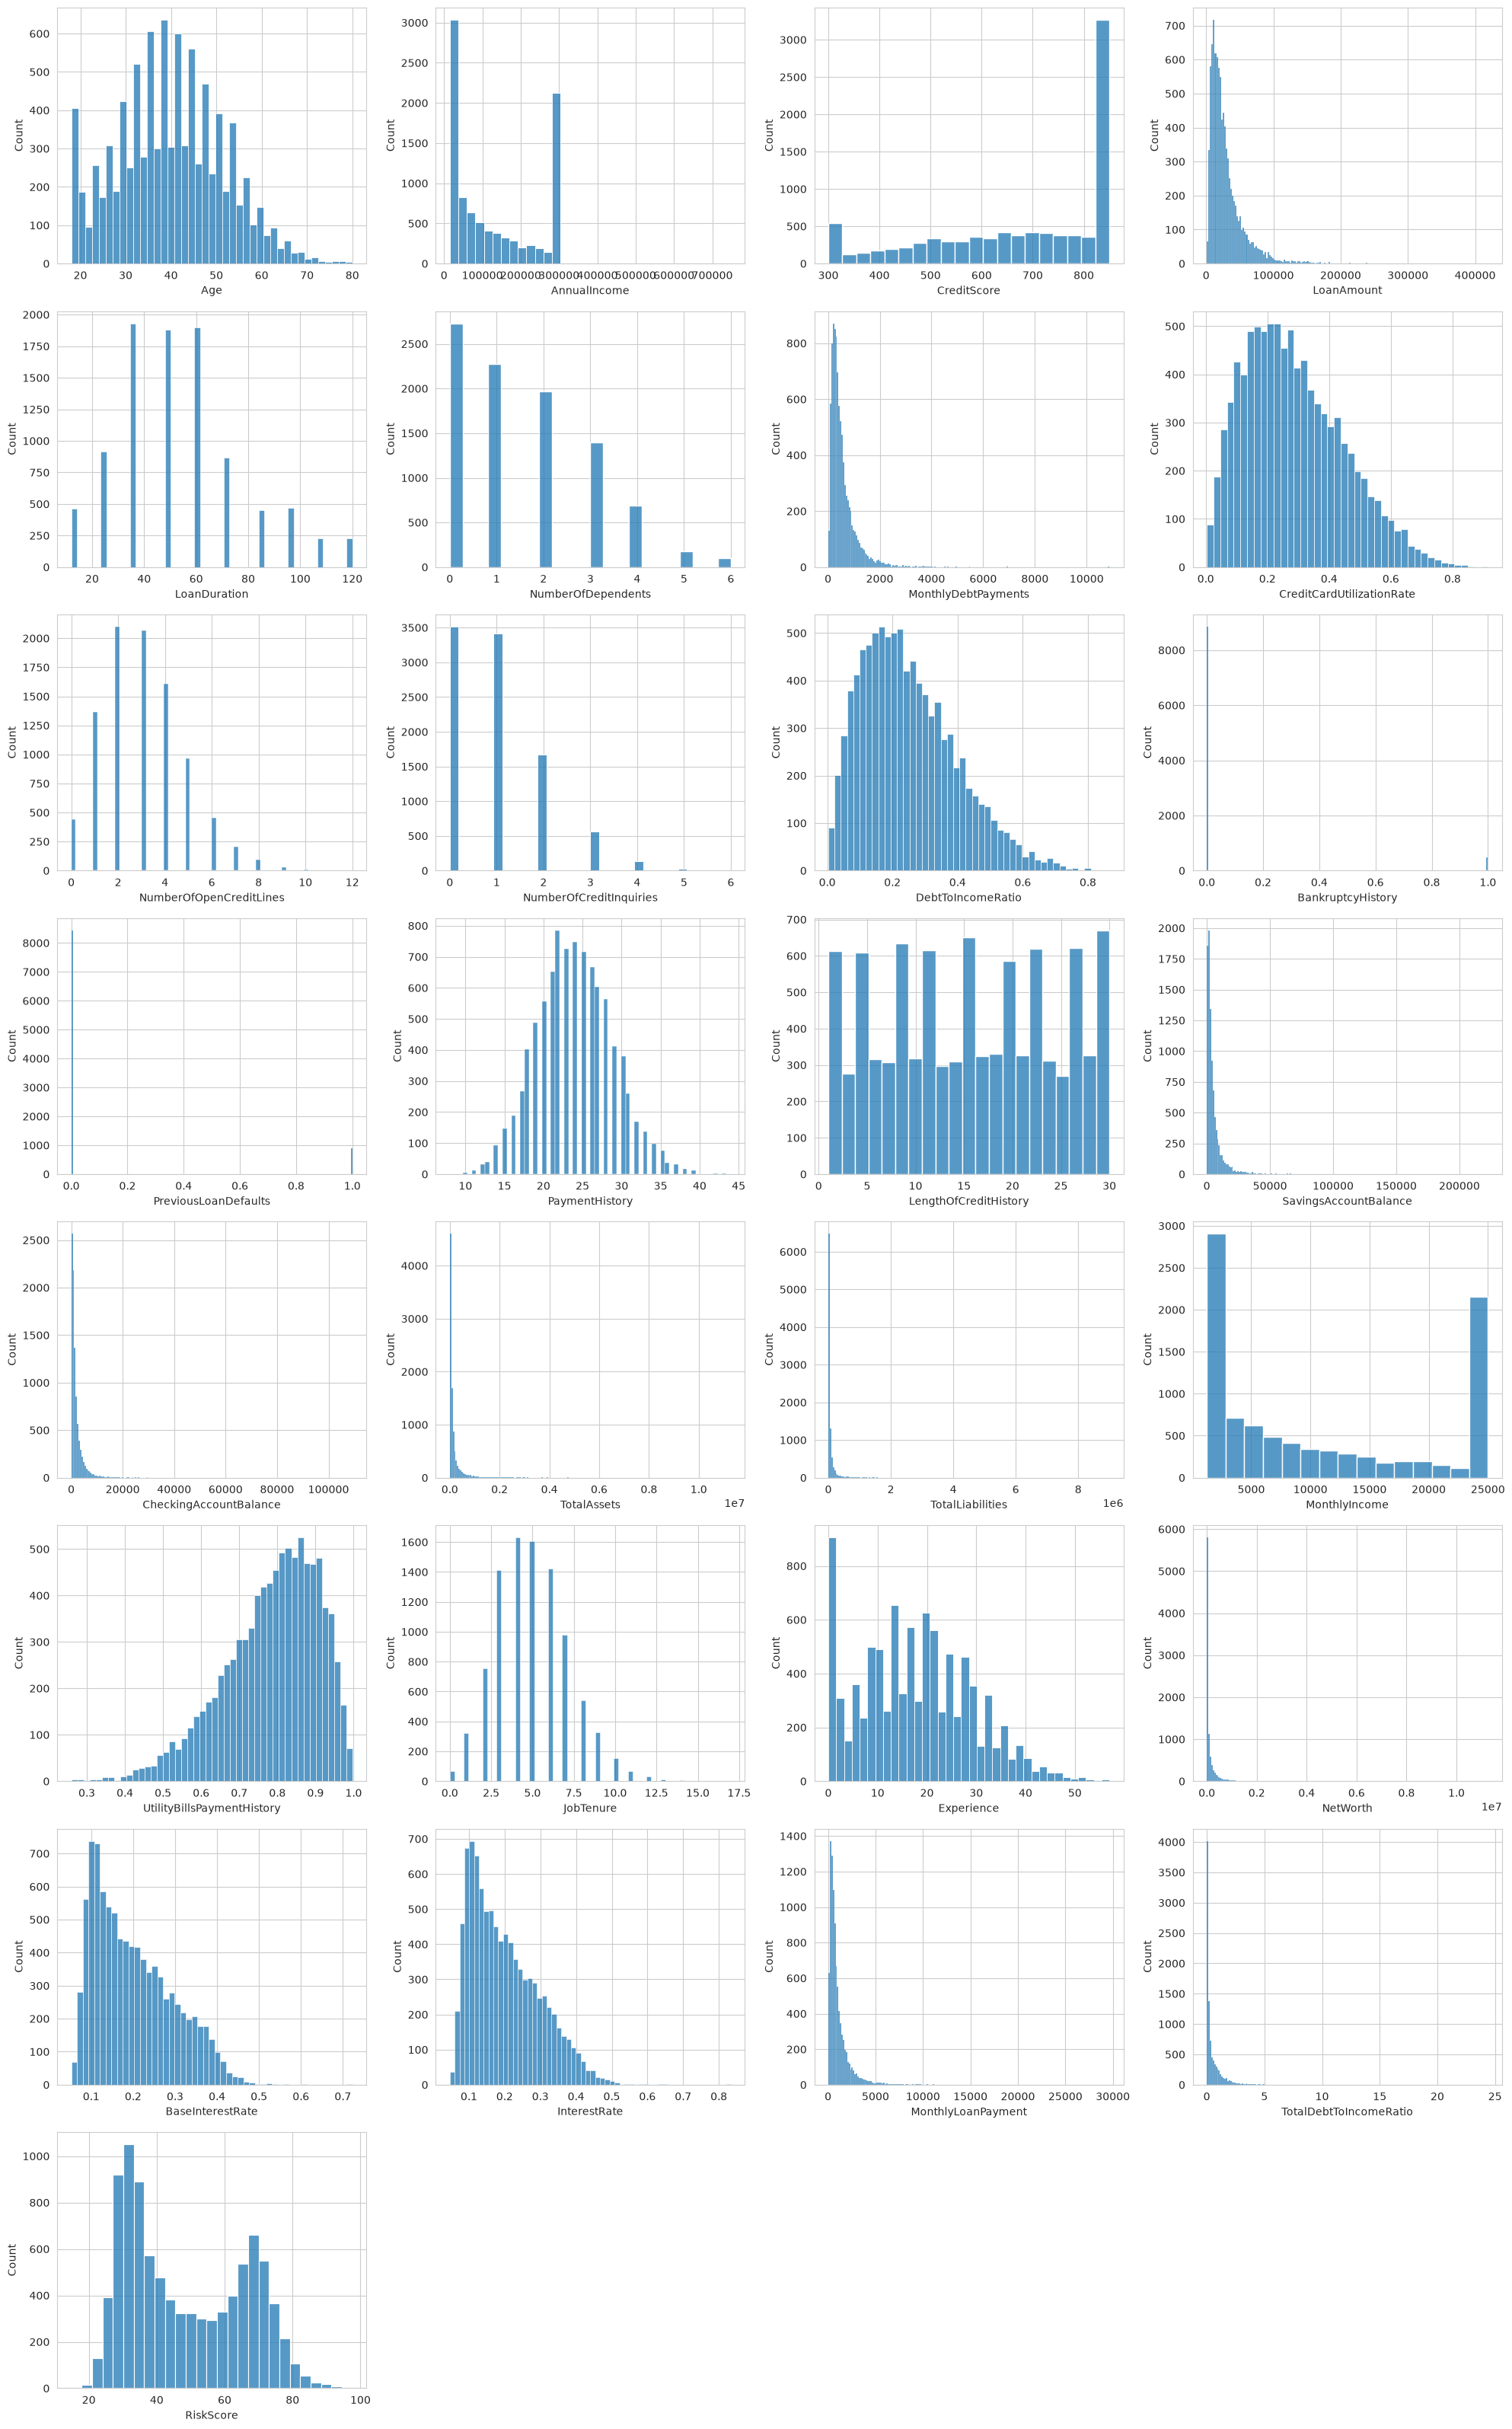

In [230]:
draw_dists(train)

Вывод: RiskScore имеет бимодальное распределение. AnnualIncome, MonthlyIncome и CreditScore имеют резко высокие столбцы по краям своих распределений. Многие признаки желательно прологарифмировать из-за наличия длинных хвостов на графиках

Сделаем распределения похожими на нормальные 

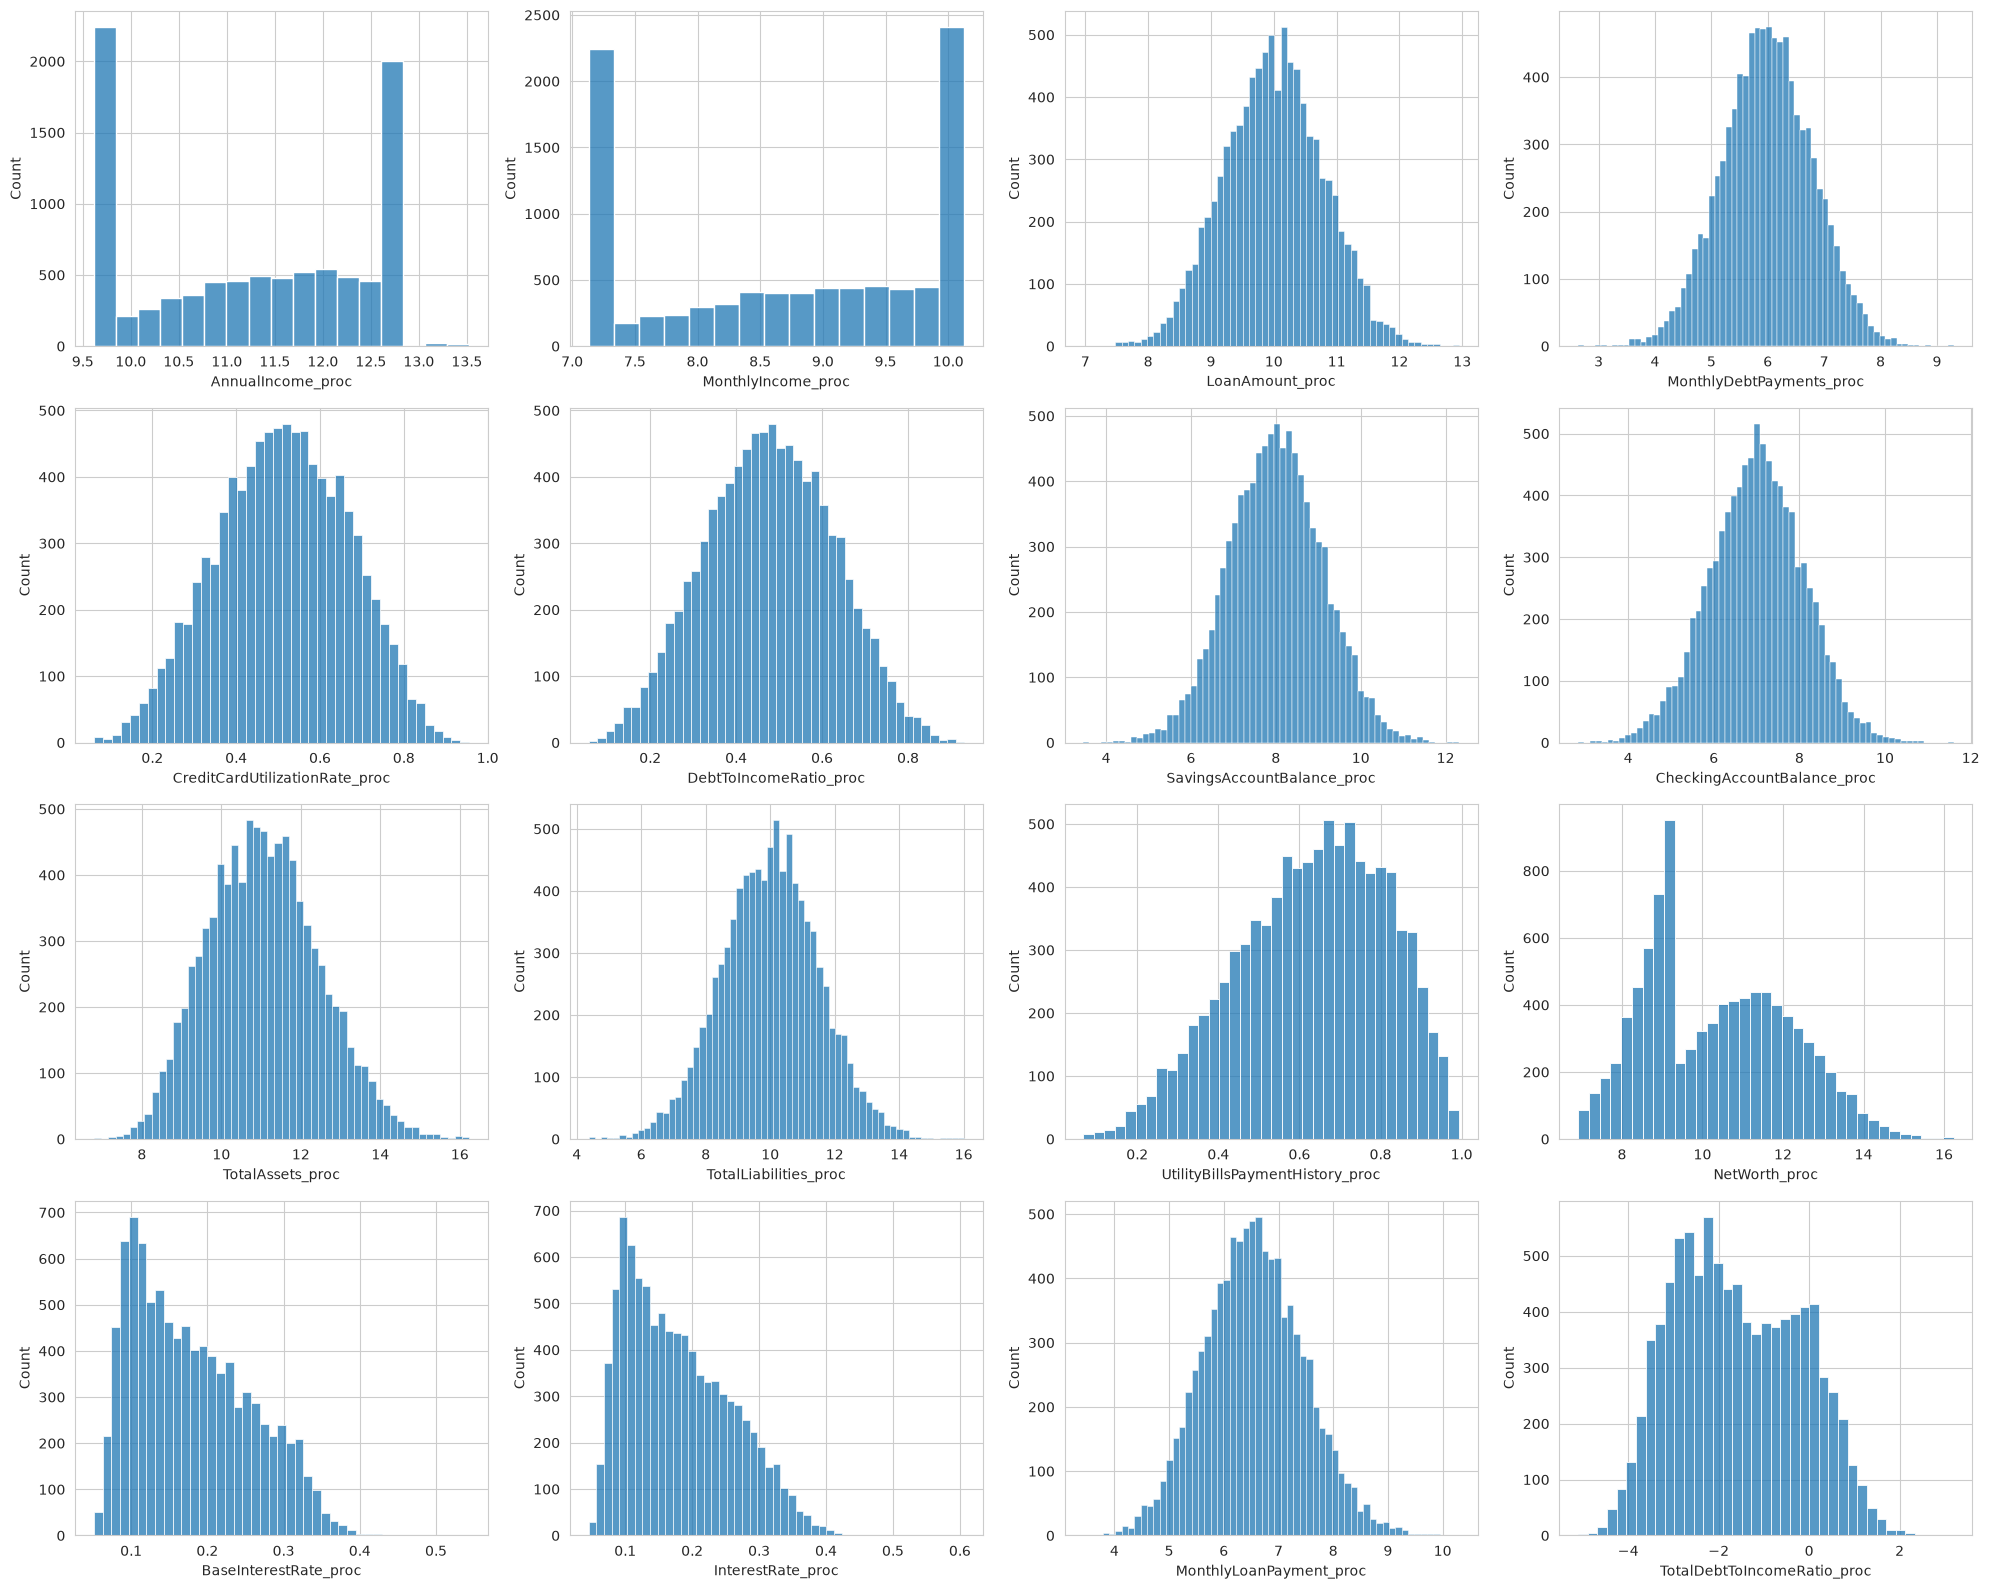

In [231]:
def add_features(df: pd.DataFrame):
    df = df.copy()

    df['ApplicationDate'] = pd.to_datetime(df['ApplicationDate'])
    df['AppMonth'] = df['ApplicationDate'].dt.month

    return df


def signed_log(s: pd.Series):
    return np.sign(s) * np.log1p(np.abs(s))


def prepare_features(df: pd.DataFrame):
    df = df.copy()

    df['AnnualIncome_proc'] = np.log1p(df['AnnualIncome'])
    df['MonthlyIncome_proc'] = np.log1p(df['MonthlyIncome'])
    df['LoanAmount_proc'] = np.log1p(df['LoanAmount'])
    df['MonthlyDebtPayments_proc'] = np.log1p(df['MonthlyDebtPayments'])

    df['CreditCardUtilizationRate_proc'] = np.sqrt(df['CreditCardUtilizationRate'])
    df['DebtToIncomeRatio_proc'] = np.sqrt(df['DebtToIncomeRatio'])

    df['SavingsAccountBalance_proc'] = signed_log(df['SavingsAccountBalance'])
    df['CheckingAccountBalance_proc'] = signed_log(df['CheckingAccountBalance'])
    df['TotalAssets_proc'] = np.log1p(df['TotalAssets'])
    df['TotalLiabilities_proc'] = signed_log(df['TotalLiabilities'])

    df['UtilityBillsPaymentHistory_proc'] = np.power(df['UtilityBillsPaymentHistory'], 2)

    df['NetWorth_proc'] = signed_log(df['NetWorth'])

    df['BaseInterestRate_proc'] = np.log1p(df['BaseInterestRate'])
    df['InterestRate_proc'] = np.log1p(df['InterestRate'])

    df['MonthlyLoanPayment_proc'] = np.log1p(df['MonthlyLoanPayment'])

    df['TotalDebtToIncomeRatio_proc'] = np.log(df['TotalDebtToIncomeRatio'])

    return df


train_orig = train.copy()
train = add_features(train)
train = prepare_features(train)
draw_dists(train.iloc[:, 36:])

Построим матрицу корреляций Пирсона

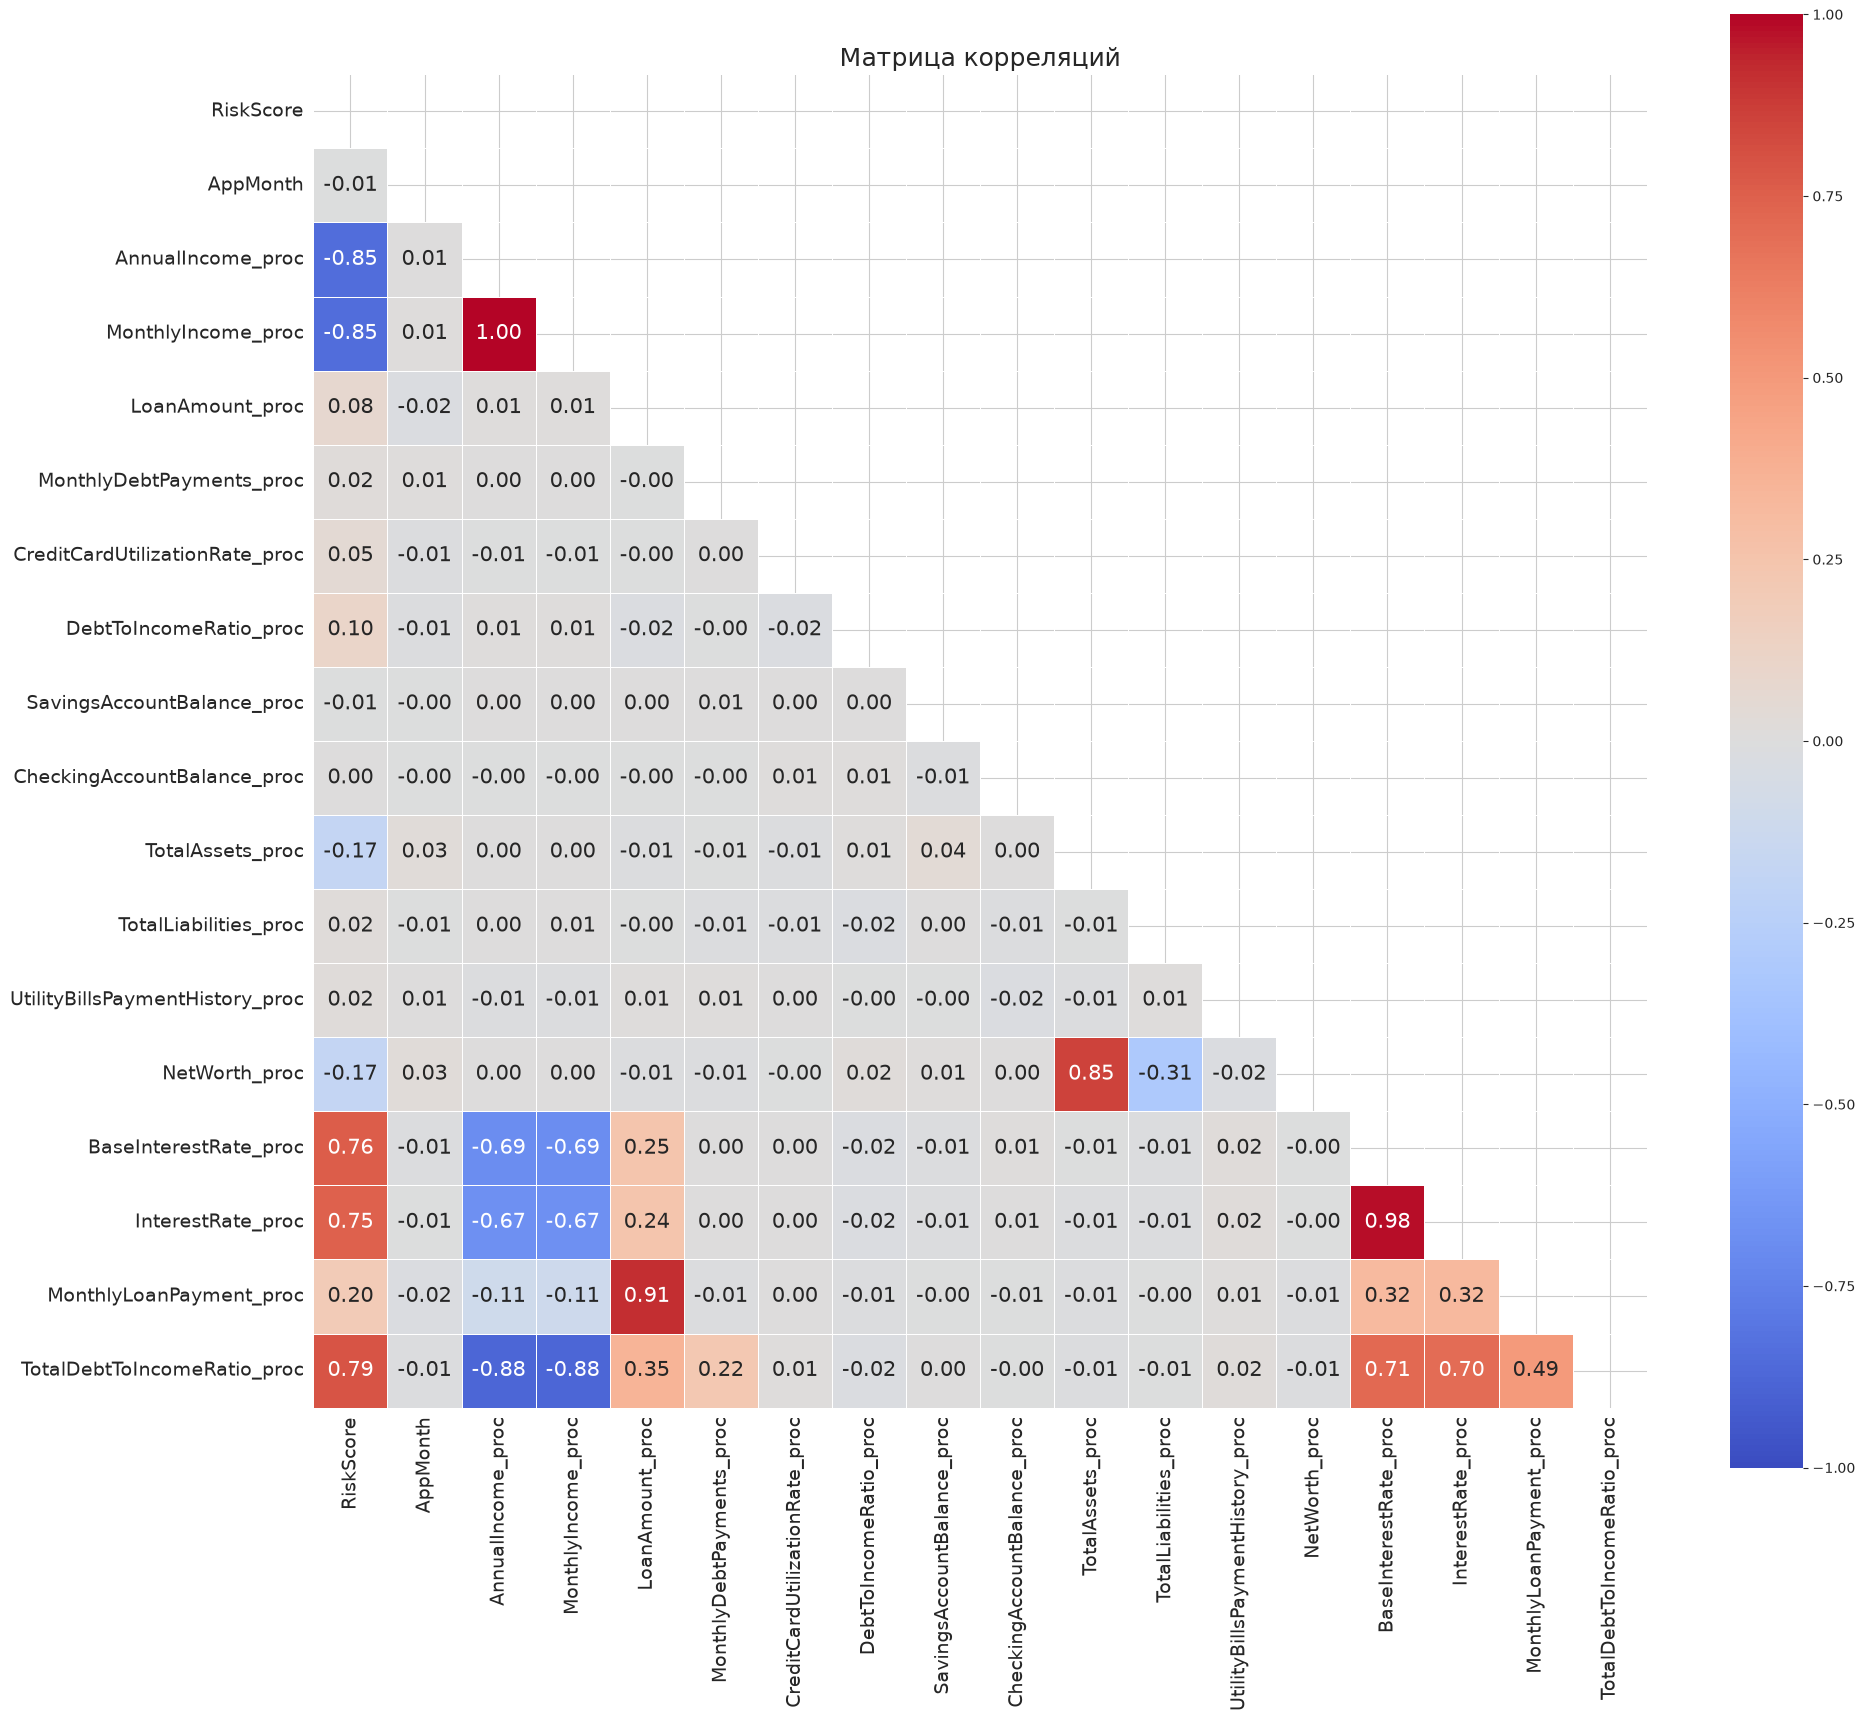

Correlation with target:
MonthlyIncome_proc                -0.847
AnnualIncome_proc                 -0.845
TotalDebtToIncomeRatio_proc        0.794
BaseInterestRate_proc              0.762
InterestRate_proc                  0.748
MonthlyLoanPayment_proc            0.201
NetWorth_proc                     -0.174
TotalAssets_proc                  -0.172
DebtToIncomeRatio_proc             0.104
LoanAmount_proc                    0.078
CreditCardUtilizationRate_proc     0.050
MonthlyDebtPayments_proc           0.021
UtilityBillsPaymentHistory_proc    0.021
TotalLiabilities_proc              0.019
SavingsAccountBalance_proc        -0.007
AppMonth                          -0.006
CheckingAccountBalance_proc        0.002
Name: RiskScore, dtype: float64

Correlation between features:
                  Feature 1                Feature 2  Correlation
         MonthlyIncome_proc        AnnualIncome_proc        0.998
          InterestRate_proc    BaseInterestRate_proc        0.977
    MonthlyLoanPa

In [232]:
def show_corr(df: pd.DataFrame):
    corr = df.corr(numeric_only=True)
    mask = np.triu(np.ones_like(corr, dtype=bool))

    plt.figure(figsize=(20, 20))
    sns.heatmap(
        corr,
        mask=mask,
        annot=True,
        fmt='.2f',
        cmap='coolwarm',
        vmin=-1,
        vmax=1,
        square=True,
        linewidths=0.5,
        cbar_kws={'shrink': 0.8},
        annot_kws={'size': 15},
    )
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.title('Матрица корреляций', fontsize=18)
    plt.tight_layout()
    plt.show()


def print_correlation(df: pd.DataFrame, target: str):
    corr = df.select_dtypes(include='number').corr(method='pearson')

    target_corr = corr[target].drop(target).sort_values(key=abs, ascending=False)

    print('Correlation with target:')
    print(target_corr.round(3))
    print()

    features_corr = corr.drop(index=target, columns=target)
    mask = np.triu(np.ones_like(features_corr, dtype=bool))

    pairs = features_corr.where(~mask).stack().reset_index()
    pairs.columns = ['Feature 1', 'Feature 2', 'Correlation']

    high_corr = pairs[pairs['Correlation'].abs() > 0.2].sort_values(
        by='Correlation', key=abs, ascending=False)

    print('Correlation between features:')
    print(high_corr.round(3).to_string(index=False))
    print()


show_corr(train.iloc[:, 34:])
print_correlation(train.iloc[:, 34:], TARGET)

Вывод: RiskScore сильнее всего коррелирует с MonthlyIncome, AnnualIncome, TotalDebtToIncomeRatio, BaseInterestRate, InterestRate. При этом важно следить за тем, что есть и сильно скоррелированные между собой признаки, например, MonthlyIncome и AnnualIncome, InterestRate и BaseInterestRate

Посмотрим на зависимости целевой переменной от признаков

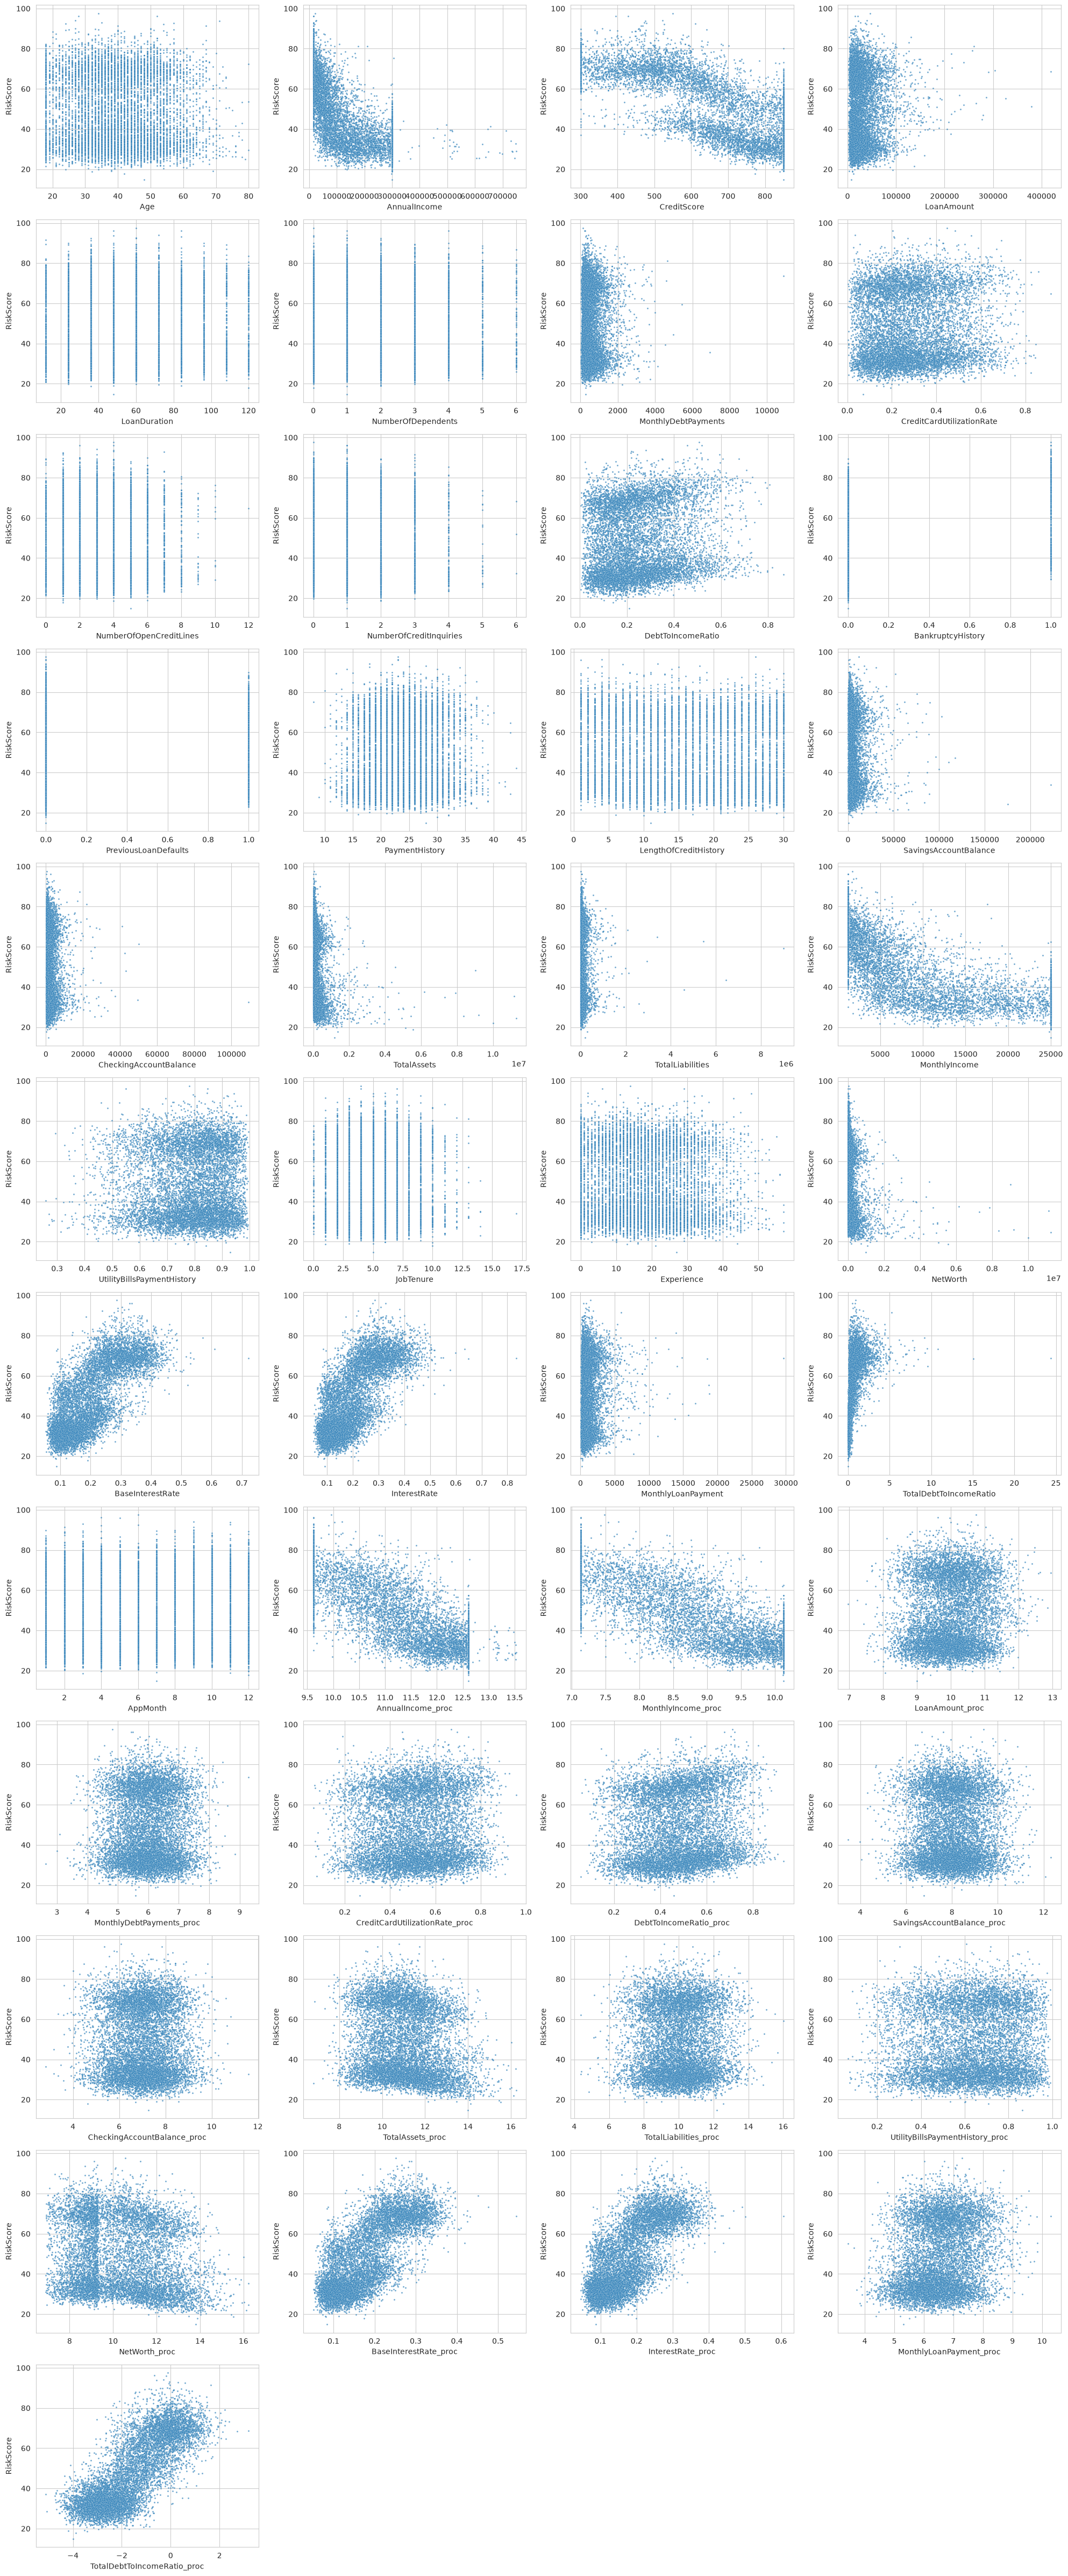

In [233]:
def draw_target_relations(df: pd.DataFrame):
    num_cols = df.select_dtypes(include='number').columns.drop(TARGET, errors='ignore')
    ncols = 4
    nrows = math.ceil(len(num_cols) / ncols)

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols * 5, nrows * 4))
    axes = axes.flatten()

    for i, col in enumerate(num_cols):
        sns.scatterplot(data=df, x=col, y=TARGET, ax=axes[i], alpha=0.6, s=5)

    for j in range(len(num_cols), len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()


draw_target_relations(train)

Вывод: видно, что объекты сгруппированы в два класса, но их нельзя четко разделить по какому-то одному признаку на графиках

На следующих графиках видна сильная корреляция между некоторыми признаками, а также зависимость целевой переменной от пар признаков

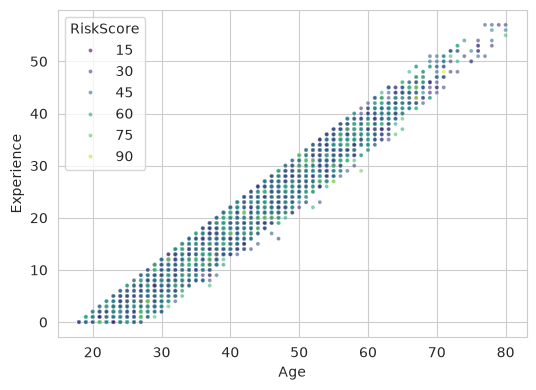

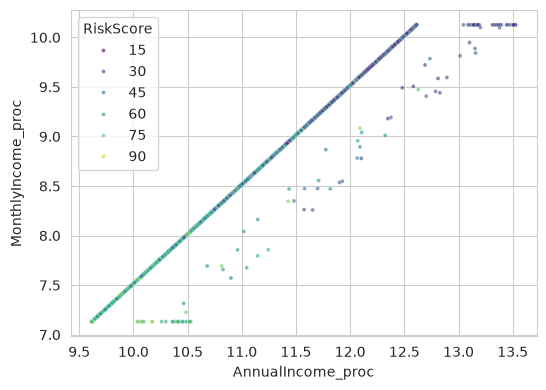

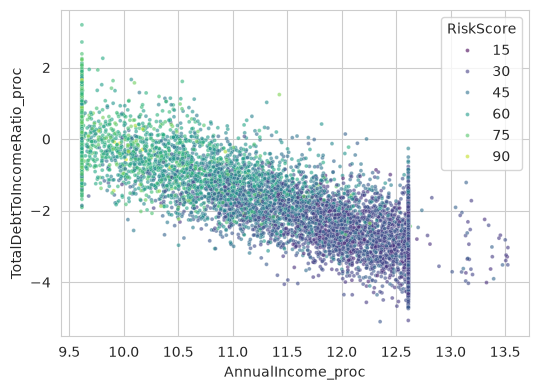

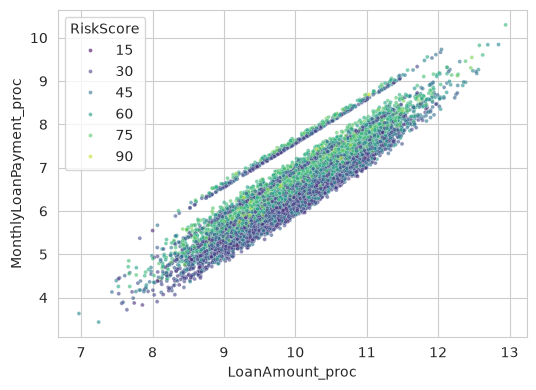

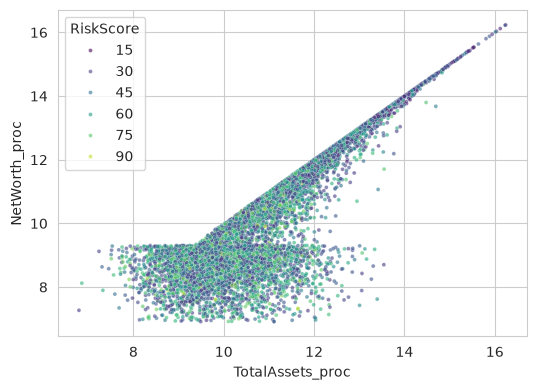

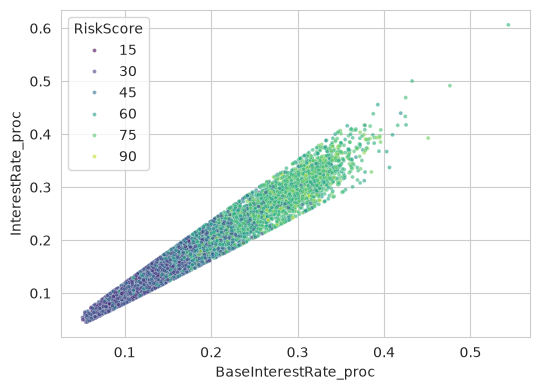

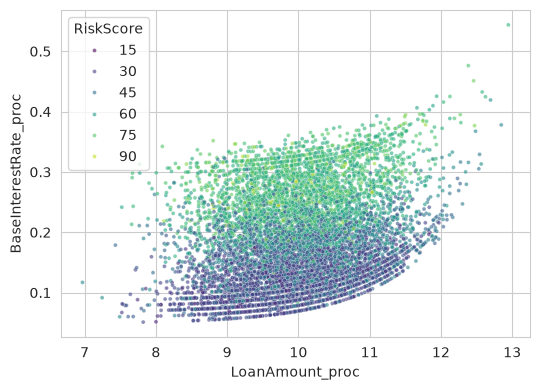

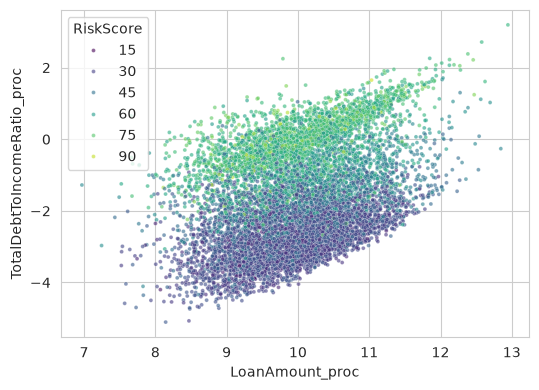

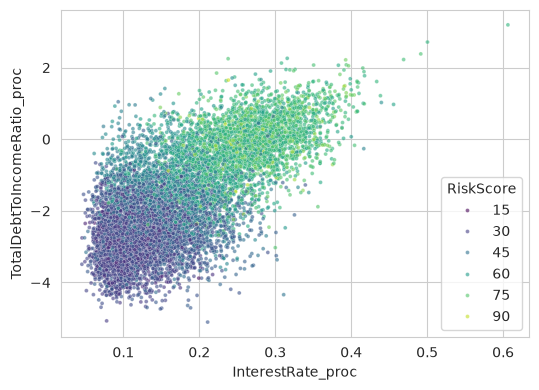

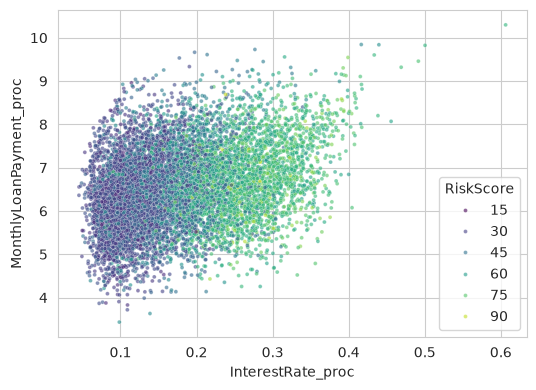

In [234]:
import itertools


def draw_feature_pairs(df: pd.DataFrame):
    num_cols = df.select_dtypes(include='number').columns.drop(TARGET, errors='ignore')
    pairs = list(itertools.combinations(num_cols, 2))

    ncols = 4
    nrows = math.ceil(len(pairs) / ncols)

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols * 5, nrows * 4))
    axes = np.atleast_1d(axes).flatten()

    for i, (col1, col2) in enumerate(pairs):
        sns.scatterplot(
            data=df,
            x=col1,
            y=col2,
            hue=TARGET,
            palette='viridis',
            ax=axes[i],
            alpha=0.6,
            s=8,
            legend=i == 0,
        )
    for j in range(len(pairs), len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()


draw_feature_pairs(train[['Age', 'Experience', TARGET]])
draw_feature_pairs(train[['AnnualIncome_proc', 'MonthlyIncome_proc', TARGET]])
draw_feature_pairs(train[['AnnualIncome_proc', 'TotalDebtToIncomeRatio_proc', TARGET]])
draw_feature_pairs(train[['LoanAmount_proc', 'MonthlyLoanPayment_proc', TARGET]])
draw_feature_pairs(train[['TotalAssets_proc', 'NetWorth_proc', TARGET]])
draw_feature_pairs(train[['BaseInterestRate_proc', 'InterestRate_proc', TARGET]])
draw_feature_pairs(train[['LoanAmount_proc', 'BaseInterestRate_proc', TARGET]])
draw_feature_pairs(train[['LoanAmount_proc', 'TotalDebtToIncomeRatio_proc', TARGET]])
draw_feature_pairs(train[['InterestRate_proc', 'TotalDebtToIncomeRatio_proc', TARGET]])
draw_feature_pairs(train[['InterestRate_proc', 'MonthlyLoanPayment_proc', TARGET]])

Посмотрим на распределения категориальных признаков

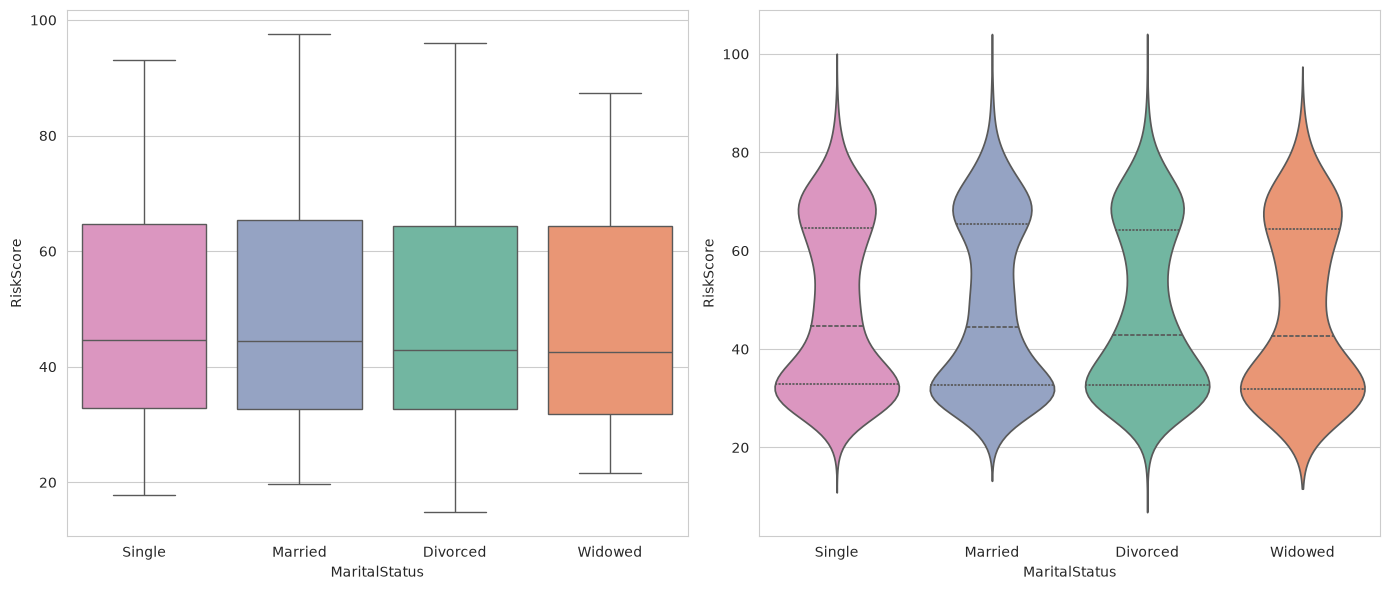

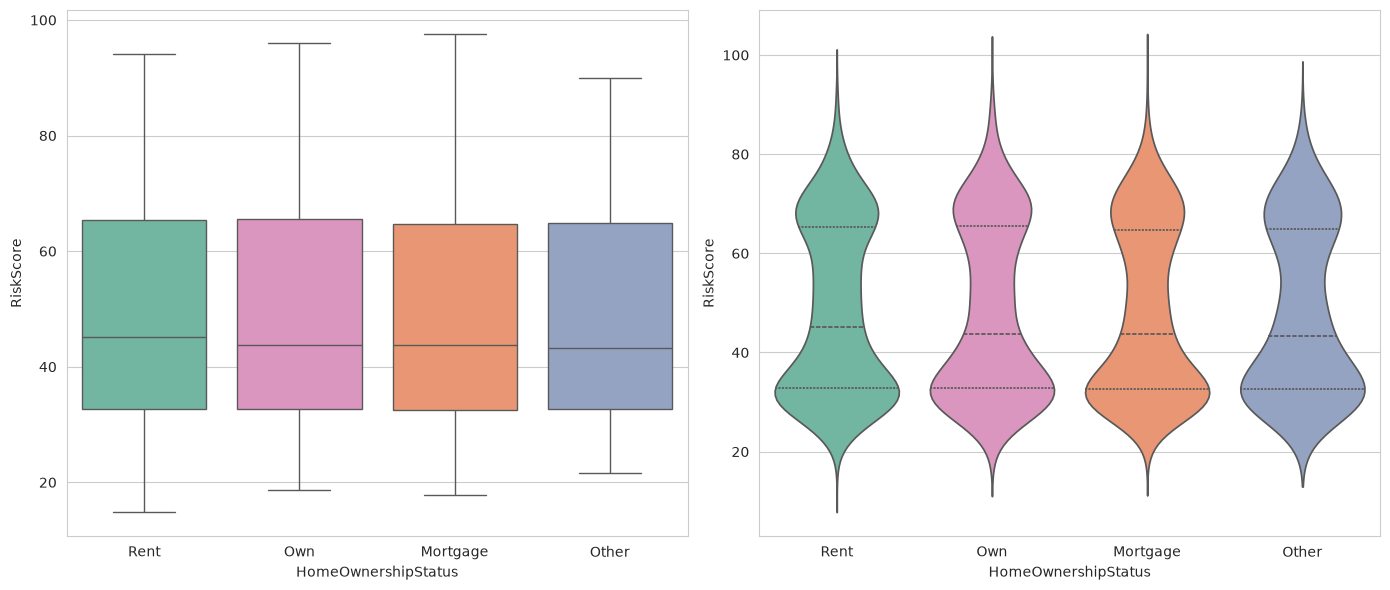

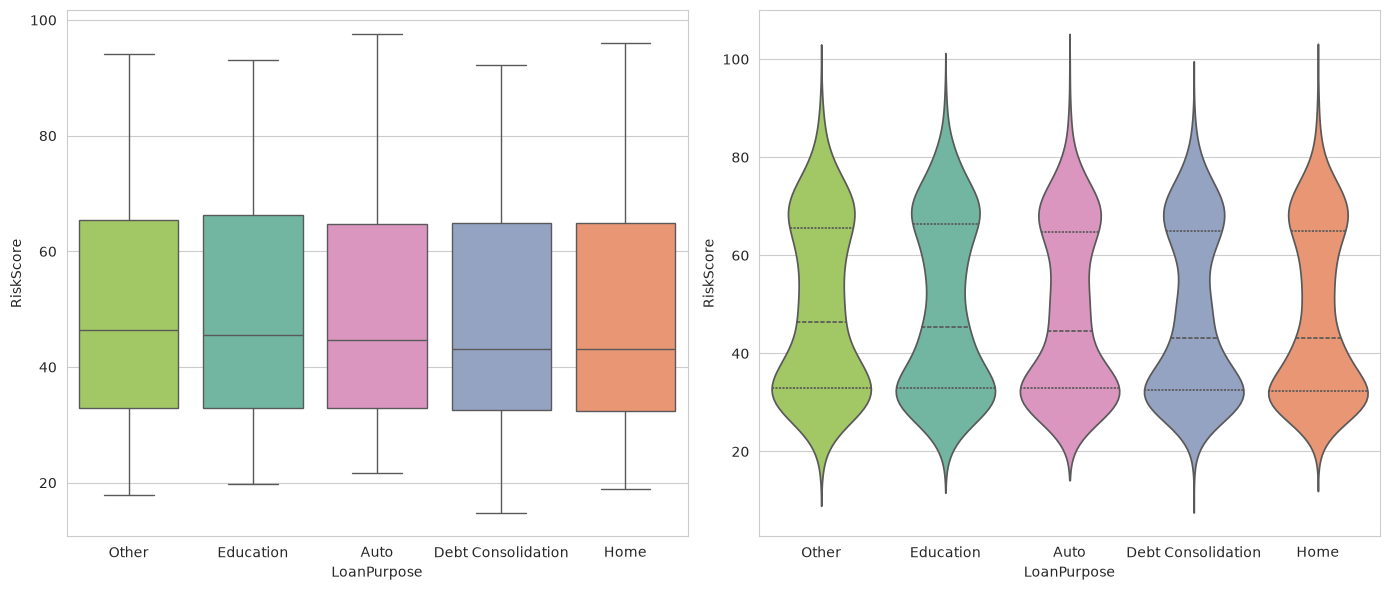

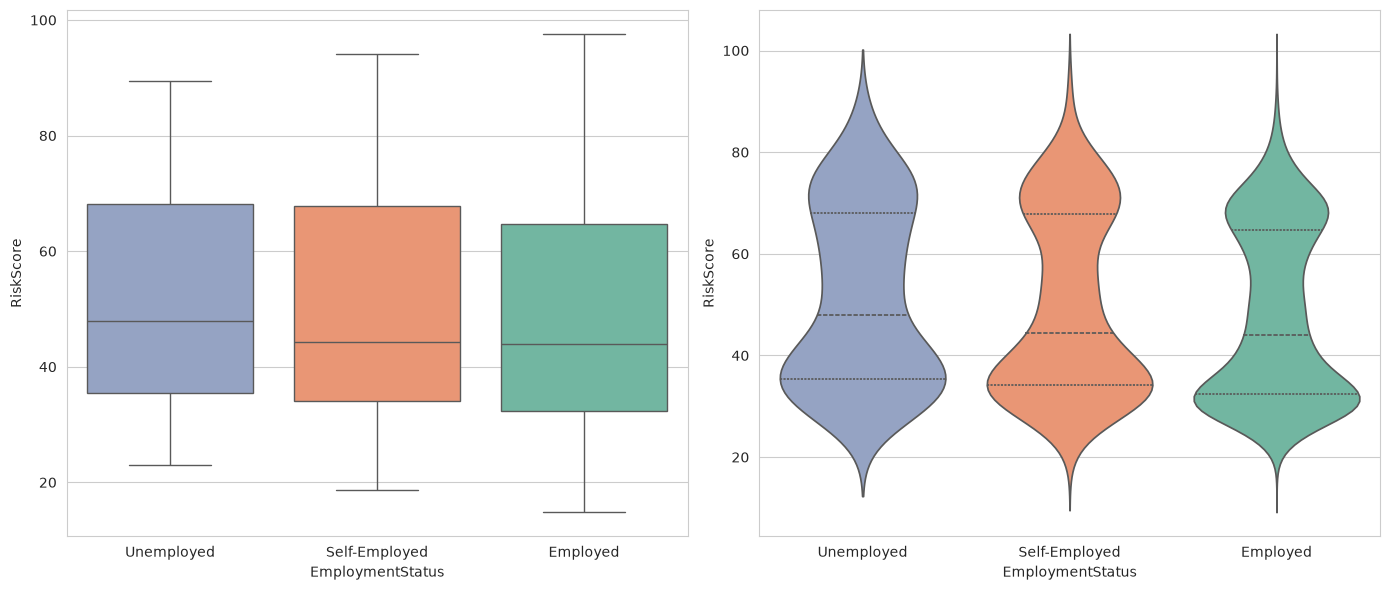

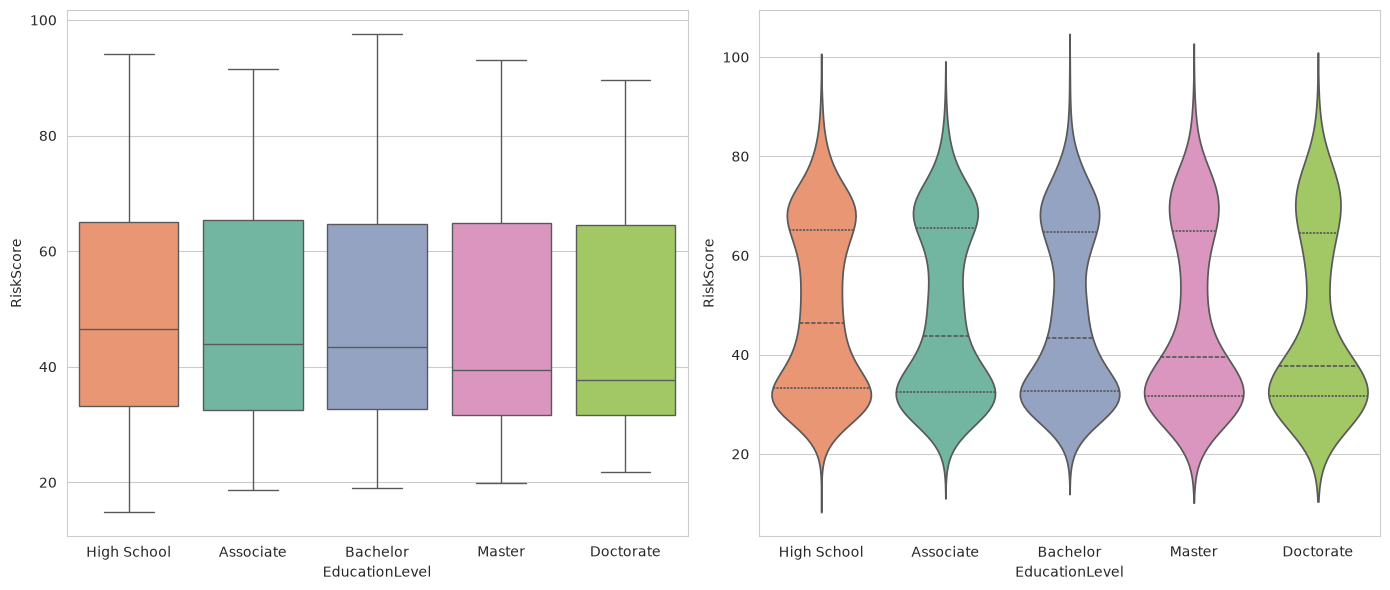

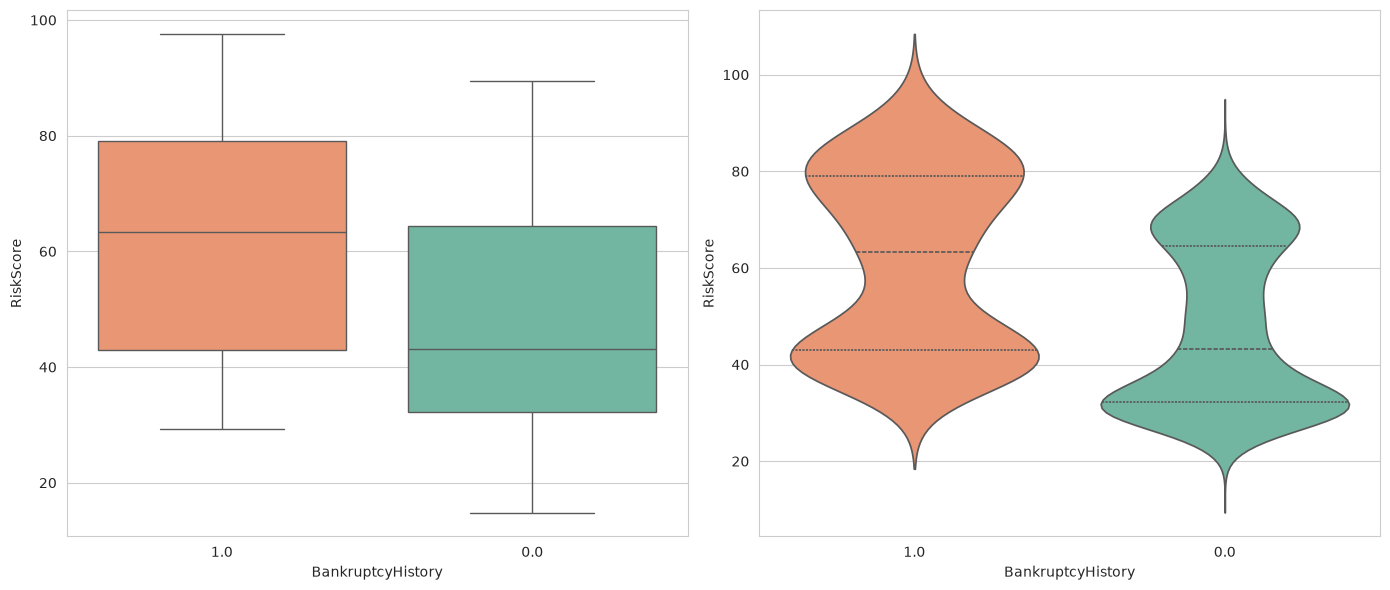

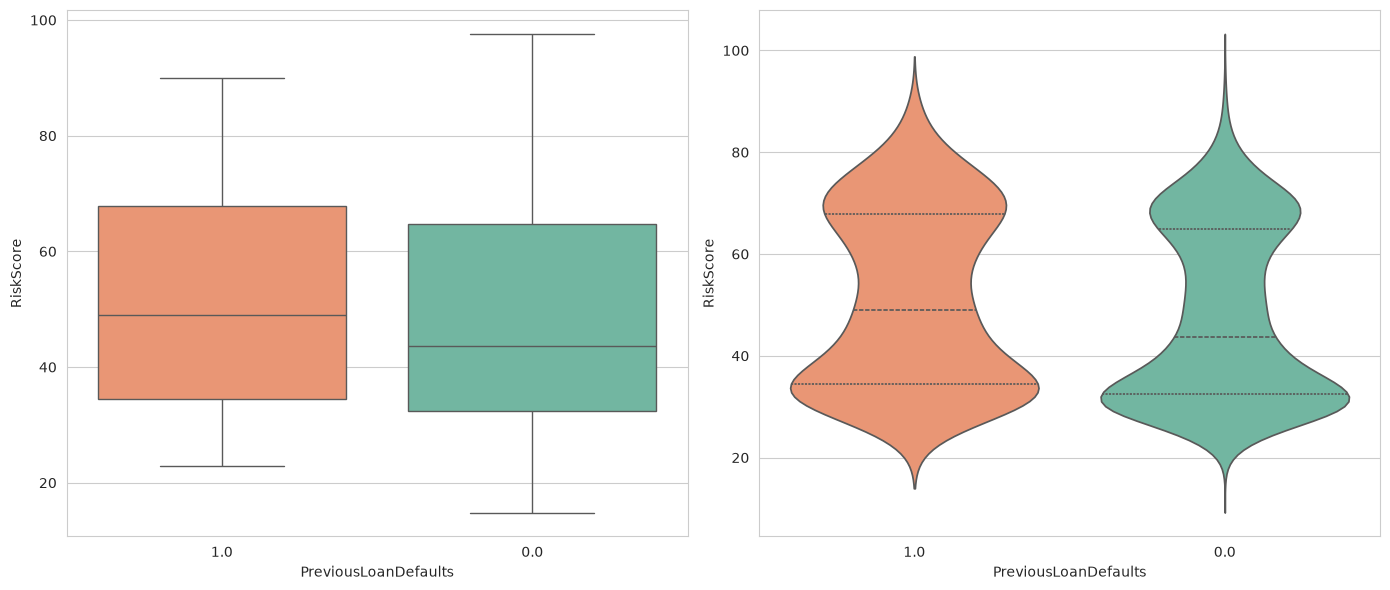

In [235]:
for ct in ['MaritalStatus', 'HomeOwnershipStatus', 'LoanPurpose', 'EmploymentStatus',
           'EducationLevel', 'BankruptcyHistory', 'PreviousLoanDefaults']:
    order = train.groupby(ct)[TARGET].median().sort_values(ascending=False).index
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    sns.set_style('whitegrid')
    sns.boxplot(
        data=train,
        x=ct,
        y=TARGET,
        order=order,
        palette='Set2',
        hue=ct,
        legend=False,
        ax=axes[0],
    )
    sns.violinplot(
        data=train,
        x=ct,
        y=TARGET,
        order=order,
        palette='Set2',
        hue=ct,
        legend=False,
        inner='quart',
        ax=axes[1],
    )
    plt.tight_layout()
    plt.show()

Вывод: на RiskScore сильно влияют история банкротств и предыдущие дефолты по кредиту. Также более высокий риск имеют безработные и люди с более низкой ступенью образования. По скрипичным диаграммам видно, что все возможные категории встречаются в обеих группах

In [236]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split

In [ ]:
def run_k_fold(linear_pipeline, X, y):
    kf = KFold(n_splits=5)

    mse_scores = []
    mae_scores = []
    r2_scores = []
    oof_preds = np.zeros(len(y))

    for fold, (train_idx, val_idx) in enumerate(kf.split(X, y)):
        X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
        X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]

        linear_pipeline.fit(X_tr, y_tr)
        preds = linear_pipeline.predict(X_va)
        oof_preds[val_idx] = preds

        fold_mse = mean_squared_error(y_va, preds)
        fold_mae = mean_absolute_error(y_va, preds)
        fold_r2 = r2_score(y_va, preds)

        mse_scores.append(fold_mse)
        mae_scores.append(fold_mae)
        r2_scores.append(fold_r2)

        print(f'Fold {fold+1} MSE: {fold_mse:.2f}, MAE: {fold_mae:.2f}, R^2: {fold_r2:.2f}')
    print()

    print(f'MSE: {mean_squared_error(y, oof_preds):.2f}')
    print(f'MAE: {mean_absolute_error(y, oof_preds):.2f}')
    print(f'R^2: {r2_score(y, oof_preds):.2f}')
    print()

In [238]:
def add_ct_risk_features(df: pd.DataFrame):
    df = df.copy()
    education_map = {
        'High School': 5,
        'Associate': 4,
        'Bachelor': 3,
        'Master': 2,
        'Doctorate': 1,
    }
    df['EmploymentStatusRisk'] = np.where(df['EmploymentStatus'] == 'Unemployed', 2, 1)
    df['EducationLevelRisk'] = df['EducationLevel'].map(education_map).fillna(0).astype(int)
    return df

Разобьем некоторые признаки на бины, чтобы модель могла найти нелинейные зависимости

In [239]:
def add_bin_features(df: pd.DataFrame):
    df = df.copy()

    rules = [
        ('CreditScoreBin', 'CreditScore', [600, 650, 700, 750]),
        ('DTIBin', 'DebtToIncomeRatio', [0.2, 0.3, 0.4, 0.5]),
        ('PaymentHistoryBin', 'PaymentHistory', [11, 18.5, 26, 33.5]),
        ('UtilizationBin', 'CreditCardUtilizationRate', [0.2, 0.4, 0.6]),
        ('CreditHistoryBin', 'LengthOfCreditHistory', [3, 5, 7, 10]),
        ('IncomeBin', 'AnnualIncome', [30000, 50000, 80000, 120000]),
        ('NetWorthBin', 'NetWorth', [50000, 100000, 250000, 500000]),
        ('BaseInterestRateBin', 'BaseInterestRate', [0.2, 0.4, 0.6, 0.8]),
        ('MonthlyLoanPaymentBin', 'MonthlyLoanPayment', [120, 480, 1900, 7500]),
    ]

    for target_col, source_col, thresholds in rules:
        df[target_col] = np.searchsorted(thresholds, df[source_col], side='right')

    return df

In [240]:
train = add_ct_risk_features(train)
train = add_bin_features(train)

In [241]:
y = train['RiskScore']
X = train.drop(columns=[TARGET, 'ApplicationDate'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

Проверим метрики на сырых признаках

In [242]:
cat_fs = ['MaritalStatus', 'HomeOwnershipStatus', 'LoanPurpose',
          'EmploymentStatus', 'EducationLevel',
          'BankruptcyHistory', 'PreviousLoanDefaults']
rest_fs = ['Age', 'AnnualIncome', 'CreditScore', 'LoanAmount', 'LoanDuration',
            'NumberOfDependents', 'MonthlyDebtPayments',
            'CreditCardUtilizationRate', 'NumberOfOpenCreditLines',
            'NumberOfCreditInquiries', 'DebtToIncomeRatio', 'PaymentHistory', 'LengthOfCreditHistory',
            'SavingsAccountBalance', 'CheckingAccountBalance', 'TotalAssets',
            'TotalLiabilities', 'MonthlyIncome', 'UtilityBillsPaymentHistory',
            'JobTenure', 'Experience', 'NetWorth', 'BaseInterestRate',
            'InterestRate', 'MonthlyLoanPayment', 'TotalDebtToIncomeRatio',
            'AppMonth']

ct = ColumnTransformer([
    ('ohe', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), cat_fs),
    ('rest', MinMaxScaler(), rest_fs)
])

linear_pipeline = Pipeline([
    ('preprocessor', ct),
    ('linear_regression', RidgeCV(alphas=np.logspace(-3, 4, 50)))
])

run_k_fold(linear_pipeline, X_train, y_train)
linear_pipeline.fit(X_train, y_train)
y_pred = linear_pipeline.predict(X_test)
print(f'Test MSE: {mean_squared_error(y_test, y_pred):.2f}')

Fold 1 MSE: 52.36, MAE: 5.79, R^2: 0.82
Fold 2 MSE: 48.62, MAE: 5.69, R^2: 0.83
Fold 3 MSE: 51.95, MAE: 5.70, R^2: 0.83
Fold 4 MSE: 52.19, MAE: 5.87, R^2: 0.83
Fold 5 MSE: 50.97, MAE: 5.74, R^2: 0.83

MSE: 51.22
MAE: 5.76
R^2: 0.83

Test MSE: 49.51


Проверим метрики на преобразованных признаках

In [243]:
cat_fs = ['MaritalStatus', 'HomeOwnershipStatus', 'LoanPurpose',
          'EmploymentStatus', 'EducationLevel',
          'BankruptcyHistory', 'PreviousLoanDefaults']
rest_fs = ['AnnualIncome_proc', 'MonthlyIncome_proc',
           'LoanAmount_proc', 'MonthlyDebtPayments_proc',
           'CreditCardUtilizationRate_proc', 'DebtToIncomeRatio_proc',
           'SavingsAccountBalance_proc', 'CheckingAccountBalance_proc',
           'TotalAssets_proc', 'TotalLiabilities_proc',
           'UtilityBillsPaymentHistory_proc', 'NetWorth_proc',
           'BaseInterestRate_proc', 'InterestRate_proc', 'MonthlyLoanPayment_proc',
           'TotalDebtToIncomeRatio_proc']

ct = ColumnTransformer([
    ('ohe', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), cat_fs),
    ('rest', MinMaxScaler(), rest_fs)
])

linear_pipeline = Pipeline([
    ('preprocessor', ct),
    ('linear_regression', RidgeCV(alphas=np.logspace(-3, 4, 50)))
])

run_k_fold(linear_pipeline, X_train, y_train)
linear_pipeline.fit(X_train, y_train)
y_pred = linear_pipeline.predict(X_test)
print(f'Test MSE: {mean_squared_error(y_test, y_pred):.2f}')

Fold 1 MSE: 40.56, MAE: 4.97, R^2: 0.86
Fold 2 MSE: 39.85, MAE: 4.98, R^2: 0.86
Fold 3 MSE: 41.46, MAE: 5.00, R^2: 0.86
Fold 4 MSE: 44.07, MAE: 5.24, R^2: 0.85
Fold 5 MSE: 39.20, MAE: 4.96, R^2: 0.87

MSE: 41.03
MAE: 5.03
R^2: 0.86

Test MSE: 39.40


Уберем сильно скоррелированные признаки

In [244]:
cat_fs = [
    'HomeOwnershipStatus',
    'EmploymentStatus',
    'BankruptcyHistory',
    'PreviousLoanDefaults',
    'MaritalStatus',
]

rest_fs = [
    'AnnualIncome_proc',
    'CreditScore',
    'BaseInterestRate_proc',
    'MonthlyLoanPayment_proc',
    'TotalAssets_proc',
    'NetWorth_proc',
    'DebtToIncomeRatio_proc',
    'LengthOfCreditHistory',
    'CreditCardUtilizationRate_proc',
    'EducationLevelRisk',
]

ct = ColumnTransformer([
    ('ohe', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), cat_fs),
    ('rest', MinMaxScaler(), rest_fs)
])

linear_pipeline = Pipeline([
    ('preprocessor', ct),
    ('linear_regression', RidgeCV(alphas=np.logspace(-3, 4, 50)))
])

run_k_fold(linear_pipeline, X_train, y_train)
linear_pipeline.fit(X_train, y_train)
y_pred = linear_pipeline.predict(X_test)
print(f'Test MSE: {mean_squared_error(y_test, y_pred):.2f}')

Fold 1 MSE: 39.51, MAE: 4.93, R^2: 0.87
Fold 2 MSE: 38.88, MAE: 4.93, R^2: 0.87
Fold 3 MSE: 41.61, MAE: 5.04, R^2: 0.86
Fold 4 MSE: 42.25, MAE: 5.17, R^2: 0.86
Fold 5 MSE: 38.37, MAE: 4.91, R^2: 0.87

MSE: 40.12
MAE: 4.99
R^2: 0.86

Test MSE: 38.60


Проверим метрики на бинах

In [245]:
cat_fs = [
    'HomeOwnershipStatus',
    'EmploymentStatus',
    'BankruptcyHistory',
    'PreviousLoanDefaults',
]

rest_fs = [
    'IncomeBin',
    'CreditScoreBin',
    'BaseInterestRateBin',
    'MonthlyLoanPaymentBin',
    'NetWorthBin',
    'DTIBin',
    'CreditHistoryBin',
    'UtilizationBin',
    'EducationLevelRisk',
]

ct = ColumnTransformer([
    ('ohe', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), cat_fs),
    ('rest', MinMaxScaler(), rest_fs)
])

linear_pipeline = Pipeline([
    ('preprocessor', ct),
    ('linear_regression', RidgeCV(alphas=np.logspace(-3, 4, 50)))
])

run_k_fold(linear_pipeline, X_train, y_train)
linear_pipeline.fit(X_train, y_train)
y_pred = linear_pipeline.predict(X_test)
print(f'Test MSE: {mean_squared_error(y_test, y_pred):.2f}')

Fold 1 MSE: 28.83, MAE: 3.99, R^2: 0.90
Fold 2 MSE: 31.10, MAE: 4.20, R^2: 0.89
Fold 3 MSE: 30.32, MAE: 4.12, R^2: 0.90
Fold 4 MSE: 29.62, MAE: 4.15, R^2: 0.90
Fold 5 MSE: 30.14, MAE: 4.21, R^2: 0.90

MSE: 30.00
MAE: 4.13
R^2: 0.90

Test MSE: 27.51


### Идея решения
Так как распределение целевой переменной бимодальное, то линейная регрессия будет проводить гиперплоскость где-то посередине и ошибаться на обеих группах. Поэтому построим смесь экспертов:
- `gate`: линейная модель, которая определяет, к какой группе относится объект
- `expert_l` и `expert_h`: две линейные модели, обученные на объектах своей группы 


`gate` будет возвращать вероятность p от 0 до 1 принадлежности объекта к верхней группе.
Итоговый результат будет равен (1 - p) $\cdot$ expert_l + p $\cdot$ expert_h

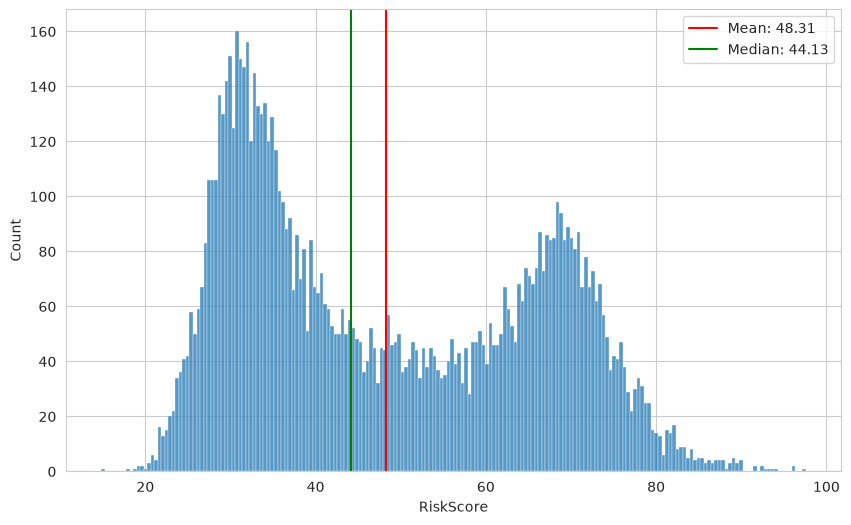

In [246]:
plt.figure(figsize=(10, 6))
sns.histplot(data=y, bins=200)

mean_val = np.mean(y)
median_val = np.median(y)

plt.axvline(
    mean_val,
    color='red',
    label=f'Mean: {mean_val:.2f}',
)
plt.axvline(
    median_val,
    color='green',
    label=f'Median: {median_val:.2f}',
)

plt.legend()
plt.show()

Разделение на группы проведем с помощью упрощенного EM-алгоритма

In [247]:
from sklearn.base import clone
from sklearn.linear_model import RidgeCV, LassoCV


def simple_EM_separation(pipeline, X, y, start_border, max_iter):
    mask_l = (y < start_border).to_numpy()
    for _ in range(max_iter):
        expert_l = clone(pipeline).fit(X.loc[mask_l], y.loc[mask_l])
        expert_h = clone(pipeline).fit(X.loc[~mask_l], y.loc[~mask_l])
        a_l = expert_l.predict(X)
        a_h = expert_h.predict(X)
        mask_l = np.abs(y.to_numpy() - a_l) < np.abs(y.to_numpy() - a_h)
    return ~mask_l, expert_l, expert_h

В качестве пайплайна модели для экспертов возьмем уже полученный ранее наилучший

In [248]:
group_h, expert_l, expert_h = simple_EM_separation(linear_pipeline, X_train, y_train, y_train.mean(), 100)
X_train['Group'] = group_h.astype(int)

Визуально оценим качество разделения на классы для обучения

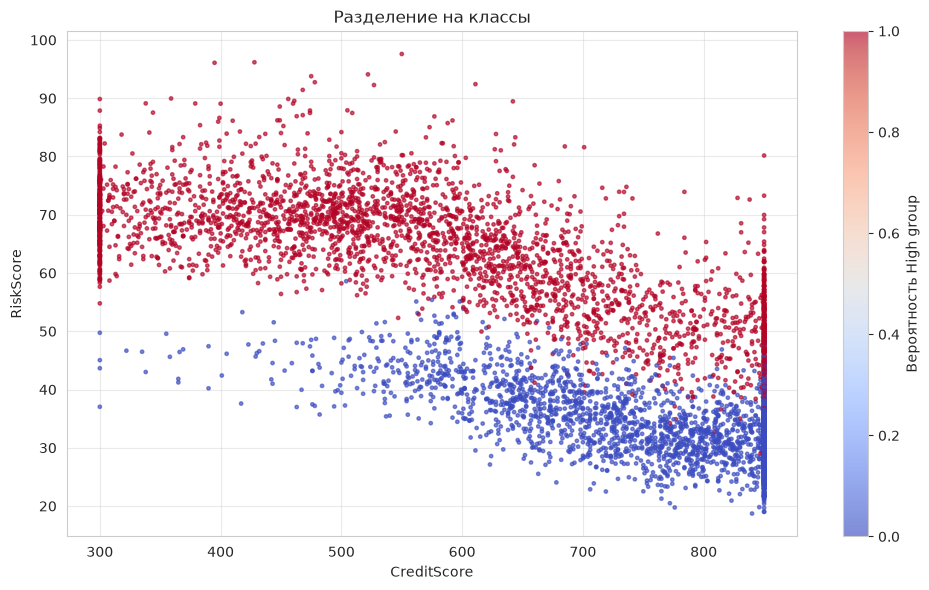

In [249]:
def draw_groups(X, y, group_h):
    plt.figure(figsize=(10, 6))
    scatter = plt.scatter(
        X['CreditScore'],
        y,
        c=group_h,
        cmap='coolwarm',
        vmin=0,
        vmax=1,
        alpha=0.65,
        s=6,
    )

    plt.title('Разделение на классы')
    plt.colorbar(scatter, label='Вероятность High group')
    plt.xlabel('CreditScore')
    plt.ylabel('RiskScore')
    plt.grid(True, alpha=0.4)
    plt.tight_layout()
    plt.show()


draw_groups(X_train, y_train, group_h)

Такое разделение будем использовать для обучения шлюза

In [250]:
def fit_gate(gate_pipeline, X, y, max_iter):
    training_set = np.full(len(X), True)
    for _ in range(max_iter):
        gate = clone(gate_pipeline).fit(X.loc[training_set], y[training_set])
        a = gate.predict(X)
        new_set = (a > 0) & (a < 1)
        if np.array_equal(training_set, new_set):
            break
        training_set = new_set
    return gate


def predict_mixture(gate, expert_l, expert_h, X):
    p = np.clip(gate.predict(X), 0, 1)
    return p, (1 - p) * expert_l.predict(X) + p * expert_h.predict(X)

In [ ]:
def build_gate_pipeline():
    cat_fs = [
        'MaritalStatus',
        'HomeOwnershipStatus',
        'LoanPurpose',
        'EmploymentStatus',
        'EducationLevel',
        'BankruptcyHistory',
        'PreviousLoanDefaults',
    ]
    rest_fs = [
        'Age',
        'AnnualIncome',
        'CreditScore',
        'LoanAmount',
        'LoanDuration',
        'NumberOfDependents',
        'MonthlyDebtPayments',
        'CreditCardUtilizationRate',
        'NumberOfOpenCreditLines',
        'NumberOfCreditInquiries',
        'DebtToIncomeRatio',
        'PaymentHistory',
        'LengthOfCreditHistory',
        'SavingsAccountBalance',
        'CheckingAccountBalance',
        'TotalAssets',
        'TotalLiabilities',
        'MonthlyIncome',
        'UtilityBillsPaymentHistory',
        'JobTenure',
        'Experience',
        'NetWorth',
        'BaseInterestRate',
        'InterestRate',
        'MonthlyLoanPayment',
        'TotalDebtToIncomeRatio',
        'AppMonth',
    ]

    gate_ct = ColumnTransformer([
        ('ohe', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), cat_fs),
        ('num', StandardScaler(), rest_fs),
    ])

    gate_pipeline = Pipeline([
        ('preprocessor', gate_ct),
        ('lasso_regression', LassoCV(alphas=np.logspace(-3, 4, 50), max_iter=10000, tol=1e-3)),
    ])

    return gate_pipeline

Проверим всю модель на кросс-валидации и на тесте

In [252]:
gate_pipeline = build_gate_pipeline()
expert_pipeline = linear_pipeline

kf = KFold(n_splits=5)

preds_risk = np.zeros(len(y_train))

mse_scores_risk = []
mae_scores_risk = []
r2_scores_risk = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X_train, y_train)):
    X_tr, y_tr = X_train.iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = X_train.iloc[val_idx], y_train.iloc[val_idx]

    group_h, expert_l, expert_h = simple_EM_separation(expert_pipeline, X_tr, y_tr, y_tr.mean(), 100)
    gate = fit_gate(gate_pipeline, X_tr, group_h, 6)

    p, risk = predict_mixture(gate, expert_l, expert_h, X_va)
    preds_risk[val_idx] = risk

    fold_mse_risk = mean_squared_error(y_va, risk)
    fold_mae_risk = mean_absolute_error(y_va, risk)
    fold_r2_risk = r2_score(y_va, risk)

    mse_scores_risk.append(fold_mse_risk)
    mae_scores_risk.append(fold_mae_risk)
    r2_scores_risk.append(fold_r2_risk)

    print(f'Fold {fold + 1} MSE: {fold_mse_risk:.2f}, MAE: {fold_mae_risk:.2f}, R^2: {fold_r2_risk:.2f}')
print()

print('RiskScore:')
print(f'MSE: {mean_squared_error(y_train, preds_risk):.2f}')
print(f'MAE: {mean_absolute_error(y_train, preds_risk):.2f}')
print(f'R^2: {r2_score(y_train, preds_risk):.2f}')
print()

Fold 1 MSE: 18.22, MAE: 2.94, R^2: 0.94
Fold 2 MSE: 19.90, MAE: 3.16, R^2: 0.93
Fold 3 MSE: 19.31, MAE: 3.06, R^2: 0.94
Fold 4 MSE: 18.95, MAE: 3.14, R^2: 0.94
Fold 5 MSE: 18.28, MAE: 2.98, R^2: 0.94

RiskScore:
MSE: 18.93
MAE: 3.06
R^2: 0.94



In [253]:
group_h, expert_l, expert_h = simple_EM_separation(expert_pipeline, X_train, y_train, y_train.mean(), 100)
gate = fit_gate(gate_pipeline, X_train, group_h, 6)
p_gate, risk = predict_mixture(gate, expert_l, expert_h, X_test)

print('RiskScore:')
print(f'MSE: {mean_squared_error(y_test, risk):.2f}')
print(f'MAE: {mean_absolute_error(y_test, risk):.2f}')
print(f'R^2: {r2_score(y_test, risk):.2f}')

RiskScore:
MSE: 17.33
MAE: 2.93
R^2: 0.94


Также посмотрим на то, как шлюз справляется на тесте

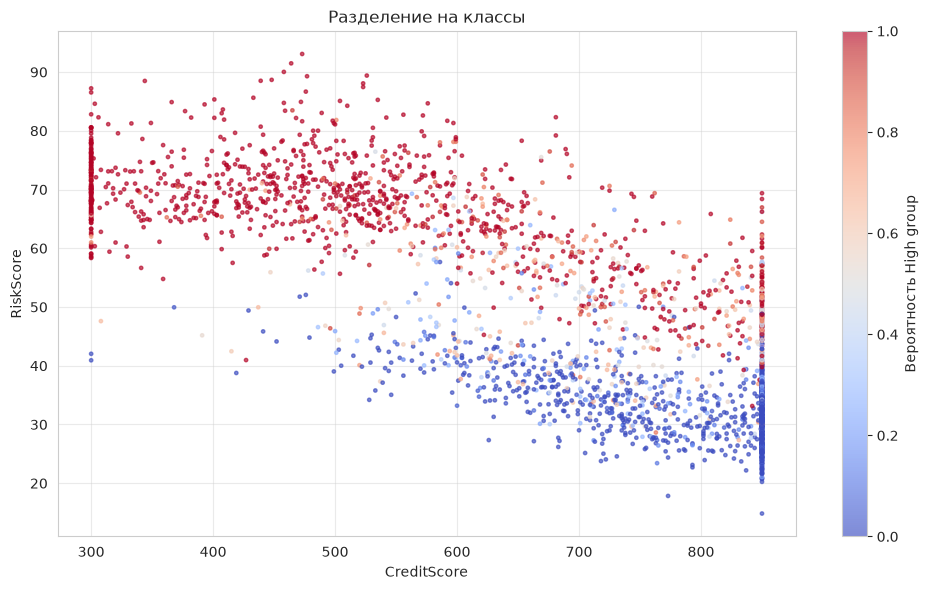

In [254]:
draw_groups(X_test, y_test, p_gate)

### Подготовка ответа на test.csv

In [255]:
group_h, expert_l, expert_h = simple_EM_separation(expert_pipeline, X, y, y.mean(), 100)
gate = fit_gate(gate_pipeline, X, group_h, 6)

X_test = pd.read_csv('test.csv')
test_id = X_test['ID']

X_test = add_features(X_test)
X_test = X_test.drop(columns=['ApplicationDate'])
X_test = prepare_features(X_test.drop(columns=['ID']))
X_test = add_ct_risk_features(X_test)
X_test = add_bin_features(X_test)

_, target = predict_mixture(gate, expert_l, expert_h, X_test)
target = np.clip(target, 0, 100)

submission = pd.DataFrame(
    {
        'ID': test_id,
        'RiskScore': target,
    }
)
submission.to_csv('answer.csv', index=False)
print('Saved')

Saved
